# 07 — Improving Accuracy: Validation, Tuning and Error-Cost Experiments
Answers the rubric question *"how could the accuracy be improved?"* with experiments.

**Protocol:** every choice (feature set, hyperparameters, decision threshold) is made with stratified
5-fold cross-validation on the **training set only**. The held-out test set is used once at the end.
All code is in `src/experiments.py`. Running it takes a few minutes.

In [1]:
import sys
from pathlib import Path

# Make the project's src/ package importable when running from notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "electrical_grid_stability.csv"

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
%matplotlib inline

In [2]:
from src.experiments import run_experiments
R = run_experiments()

1. Cross-validating baseline models...


              Model  cv_accuracy_mean  cv_accuracy_std  cv_macro_f1_mean  cv_macro_f1_std  cv_roc_auc_mean  cv_roc_auc_std  cv_train_accuracy_mean  full_train_accuracy  test_accuracy
Logistic Regression            0.8146           0.0072            0.7956           0.0080           0.8895          0.0067                  0.8144                0.814          0.820
      Random Forest            0.9162           0.0109            0.9078           0.0118           0.9777          0.0041                  1.0000                1.000          0.929

2. Feature-group ablation (CV on training set)...


             Feature set               Model  n_features  cv_accuracy  cv_macro_f1  cv_macro_f1_std
         All 12 features Logistic Regression          12       0.8146       0.7956           0.0080
         All 12 features       Random Forest          12       0.9162       0.9078           0.0118
Without p1 (11 features) Logistic Regression          11       0.8146       0.7956           0.0080
Without p1 (11 features)       Random Forest          11       0.9186       0.9105           0.0109
 Without p1-p4 (tau + g) Logistic Regression           8       0.8125       0.7931           0.0070
 Without p1-p4 (tau + g)       Random Forest           8       0.9221       0.9145           0.0076
                tau only Logistic Regression           4       0.7321       0.6945           0.0123
                tau only       Random Forest           4       0.7594       0.7324           0.0081
                  g only Logistic Regression           4       0.7191       0.6745           0.0152



4. Tuning Logistic Regression (with/without polynomial features)...


   Tuning Random Forest...


...

   Random Forest (tuned): threshold for >=98% unstable recall = 0.4



6. Final held-out test evaluation...


                                                             Model threshold  accuracy  macro_f1  roc_auc  unstable_precision  unstable_recall  stable_recall  false_stable  false_unstable
                               Majority baseline (always unstable)         -    0.6380    0.3895   0.5000              0.6380           1.0000         0.0000             0             724
                                               Logistic Regression       0.5    0.8200    0.8009   0.8920              0.8408           0.8856         0.7044           146             214
                                                     Random Forest       0.5    0.9290    0.9220   0.9823              0.9289           0.9624         0.8702            48              94
                           Logistic Regression (tuned, polynomial)       0.5    0.9555    0.9518   0.9897              0.9655           0.9647         0.9392            45              44
                                             Random Forest (


7. Permutation importance on test set...



Experiments complete. Results saved to outputs/metrics and outputs/figures.


## 1. Cross-validation and overfitting

In [3]:
R["cv"].T

,0,1
Model,Logistic Regression,Random Forest
cv_accuracy_mean,0.8146,0.9162
cv_accuracy_std,0.0072,0.0109
cv_macro_f1_mean,0.7956,0.9078
cv_macro_f1_std,0.008,0.0118
cv_roc_auc_mean,0.8895,0.9777
cv_roc_auc_std,0.0067,0.0041
cv_train_accuracy_mean,0.8144,1.0
full_train_accuracy,0.814,1.0
test_accuracy,0.82,0.929


CV scores have small standard deviations (< 0.012), so the test results are not a lucky split. Random Forest's 100% training accuracy vs ≈ 92% CV accuracy confirms overfitting; Logistic Regression shows none.

## 2. Feature-group ablation

In [4]:
R["ablation"].pivot(index="Feature set", columns="Model", values="cv_macro_f1")

Model,Logistic Regression,Random Forest
Feature set,,
All 12 features,0.7956,0.9078
Without p1 (11 features),0.7956,0.9105
Without p1-p4 (tau + g),0.7931,0.9145
g only,0.6745,0.6520
p only,0.3895,0.4817
tau only,0.6945,0.7324


**Interpretation:**
- Dropping the redundant `p1` changes Logistic Regression **not at all** (identical scores) and
  slightly helps Random Forest — confirming `p1` carries no extra information.
- Removing all four power features barely changes LR and slightly *improves* RF: on their own the
  `p` features are no better than the baseline (LR macro-F1 0.39 = always-unstable).
- Neither `tau` alone nor `g` alone is enough (macro-F1 ≈ 0.65–0.73); stability depends on how
  reaction times **and** elasticities combine.

## 3. Hyperparameter tuning

In [5]:
print("Best parameters:", R["best_params"])
R["tuning"].groupby("Model").head(5)

Best parameters: {'Logistic Regression': {'classifier__C': 10, 'poly__degree': 2}, 'Random Forest': {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1}}


,Model,params,cv_macro_f1_mean,cv_macro_f1_std,rank
7,Logistic Regression,"{'classifier__C': 10, 'poly__degree': 2}",0.9337,0.0074,1
9,Logistic Regression,"{'classifier__C': 100, 'poly__degree': 2}",0.9333,0.0069,2
5,Logistic Regression,"{'classifier__C': 1, 'poly__degree': 2}",0.9332,0.0073,3
3,Logistic Regression,"{'classifier__C': 0.1, 'poly__degree': 2}",0.9218,0.0049,4
1,Logistic Regression,"{'classifier__C': 0.01, 'poly__degree': 2}",0.8695,0.0089,5
18,Random Forest,"{'max_depth': 20, 'max_features': 'sqrt', 'min...",0.9102,0.0102,1
10,Random Forest,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.9099,0.0103,2
11,Random Forest,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.9077,0.0079,3
19,Random Forest,"{'max_depth': 20, 'max_features': 'sqrt', 'min...",0.9077,0.0079,3
14,Random Forest,"{'max_depth': 12, 'max_features': 'sqrt', 'min...",0.9075,0.0118,5


**Interpretation:**
- For Logistic Regression, adding **degree-2 polynomial features** (squares and pairwise products
  such as `tau1·g1`) is by far the largest improvement: CV macro-F1 rises from ≈ 0.80 to ≈ 0.93. The
  linear model was limited by its *features*, not by the algorithm — once interaction terms exist,
  a linear boundary in that expanded space separates the classes well.
- For Random Forest, tuning depth, leaf size and `max_features` changes CV macro-F1 by less than
  0.01: the default forest was already close to its best on this data.

## 4. Decision threshold vs missed instabilities

Chosen thresholds (>= 98% unstable recall on training folds): {'Logistic Regression (tuned, polynomial)': np.float64(0.25), 'Random Forest (tuned)': np.float64(0.4)}


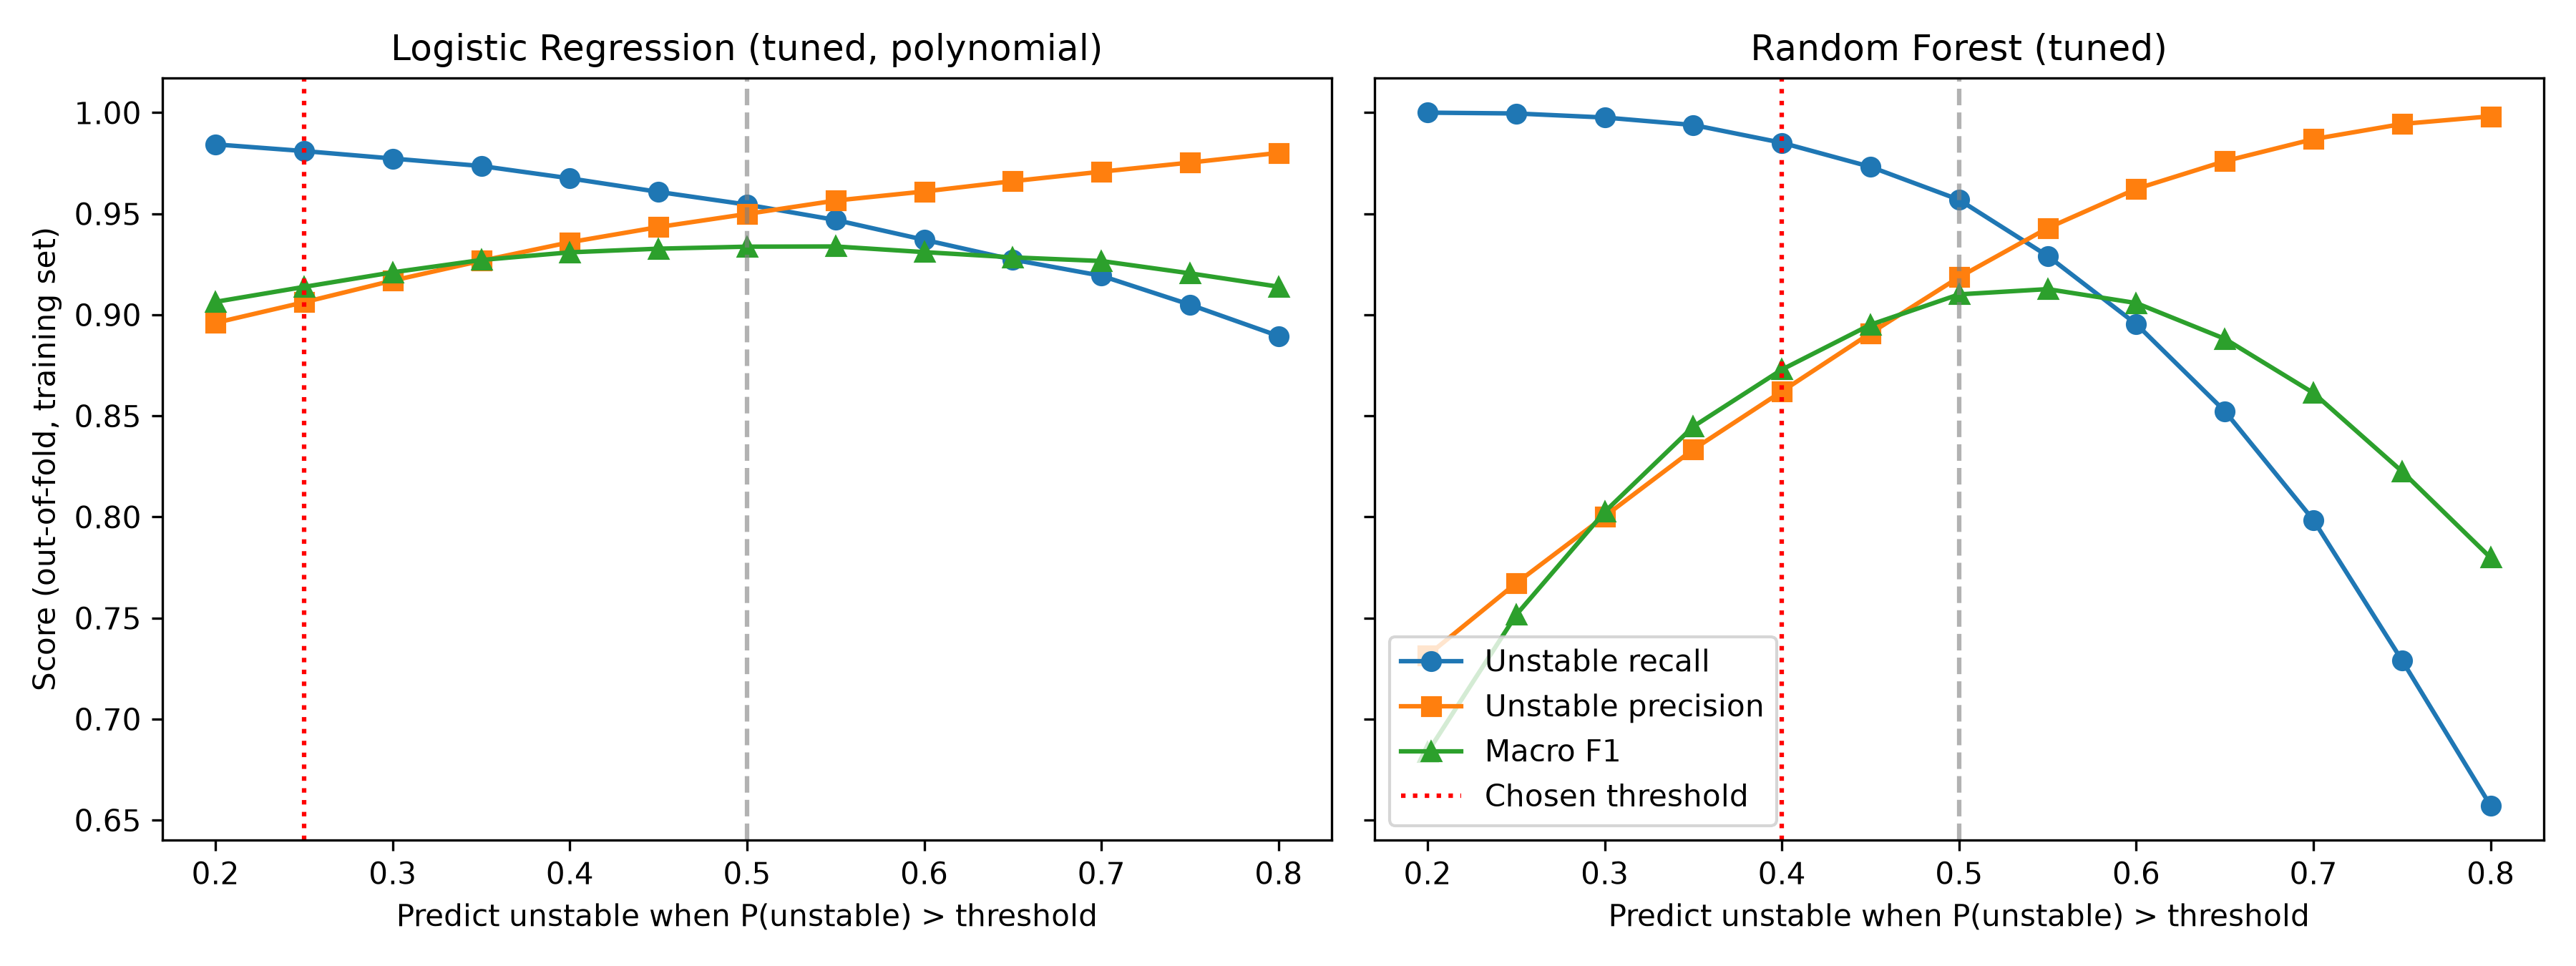

In [6]:
from IPython.display import Image
print("Chosen thresholds (>= 98% unstable recall on training folds):", R["chosen_thresholds"])
Image(str(PROJECT_ROOT / "outputs" / "figures" / "threshold_tradeoff.png"), width=900)

Lowering the threshold trades false alarms for fewer missed instabilities. The threshold is chosen on out-of-fold training probabilities, then applied unchanged to the test set.

## 5. Final held-out test comparison

In [7]:
R["final"]

,Model,threshold,accuracy,macro_f1,roc_auc,unstable_precision,unstable_recall,stable_recall,false_stable,false_unstable
0,Majority baseline (always unstable),-,0.6380,0.3895,0.5000,0.6380,1.0000,0.0000,0,724
1,Logistic Regression,0.5,0.8200,0.8009,0.8920,0.8408,0.8856,0.7044,146,214
2,Random Forest,0.5,0.9290,0.9220,0.9823,0.9289,0.9624,0.8702,48,94
3,"Logistic Regression (tuned, polynomial)",0.5,0.9555,0.9518,0.9897,0.9655,0.9647,0.9392,45,44
4,Random Forest (tuned),0.5,0.9270,0.9201,0.9829,0.9306,0.9569,0.8743,55,91
5,"Logistic Regression (tuned, polynomial), recal...",0.25,0.9405,0.9338,0.9897,0.9251,0.9867,0.8591,17,102
6,"Random Forest (tuned), recall-oriented threshold",0.4,0.8980,0.8827,0.9829,0.8707,0.9867,0.7417,17,187


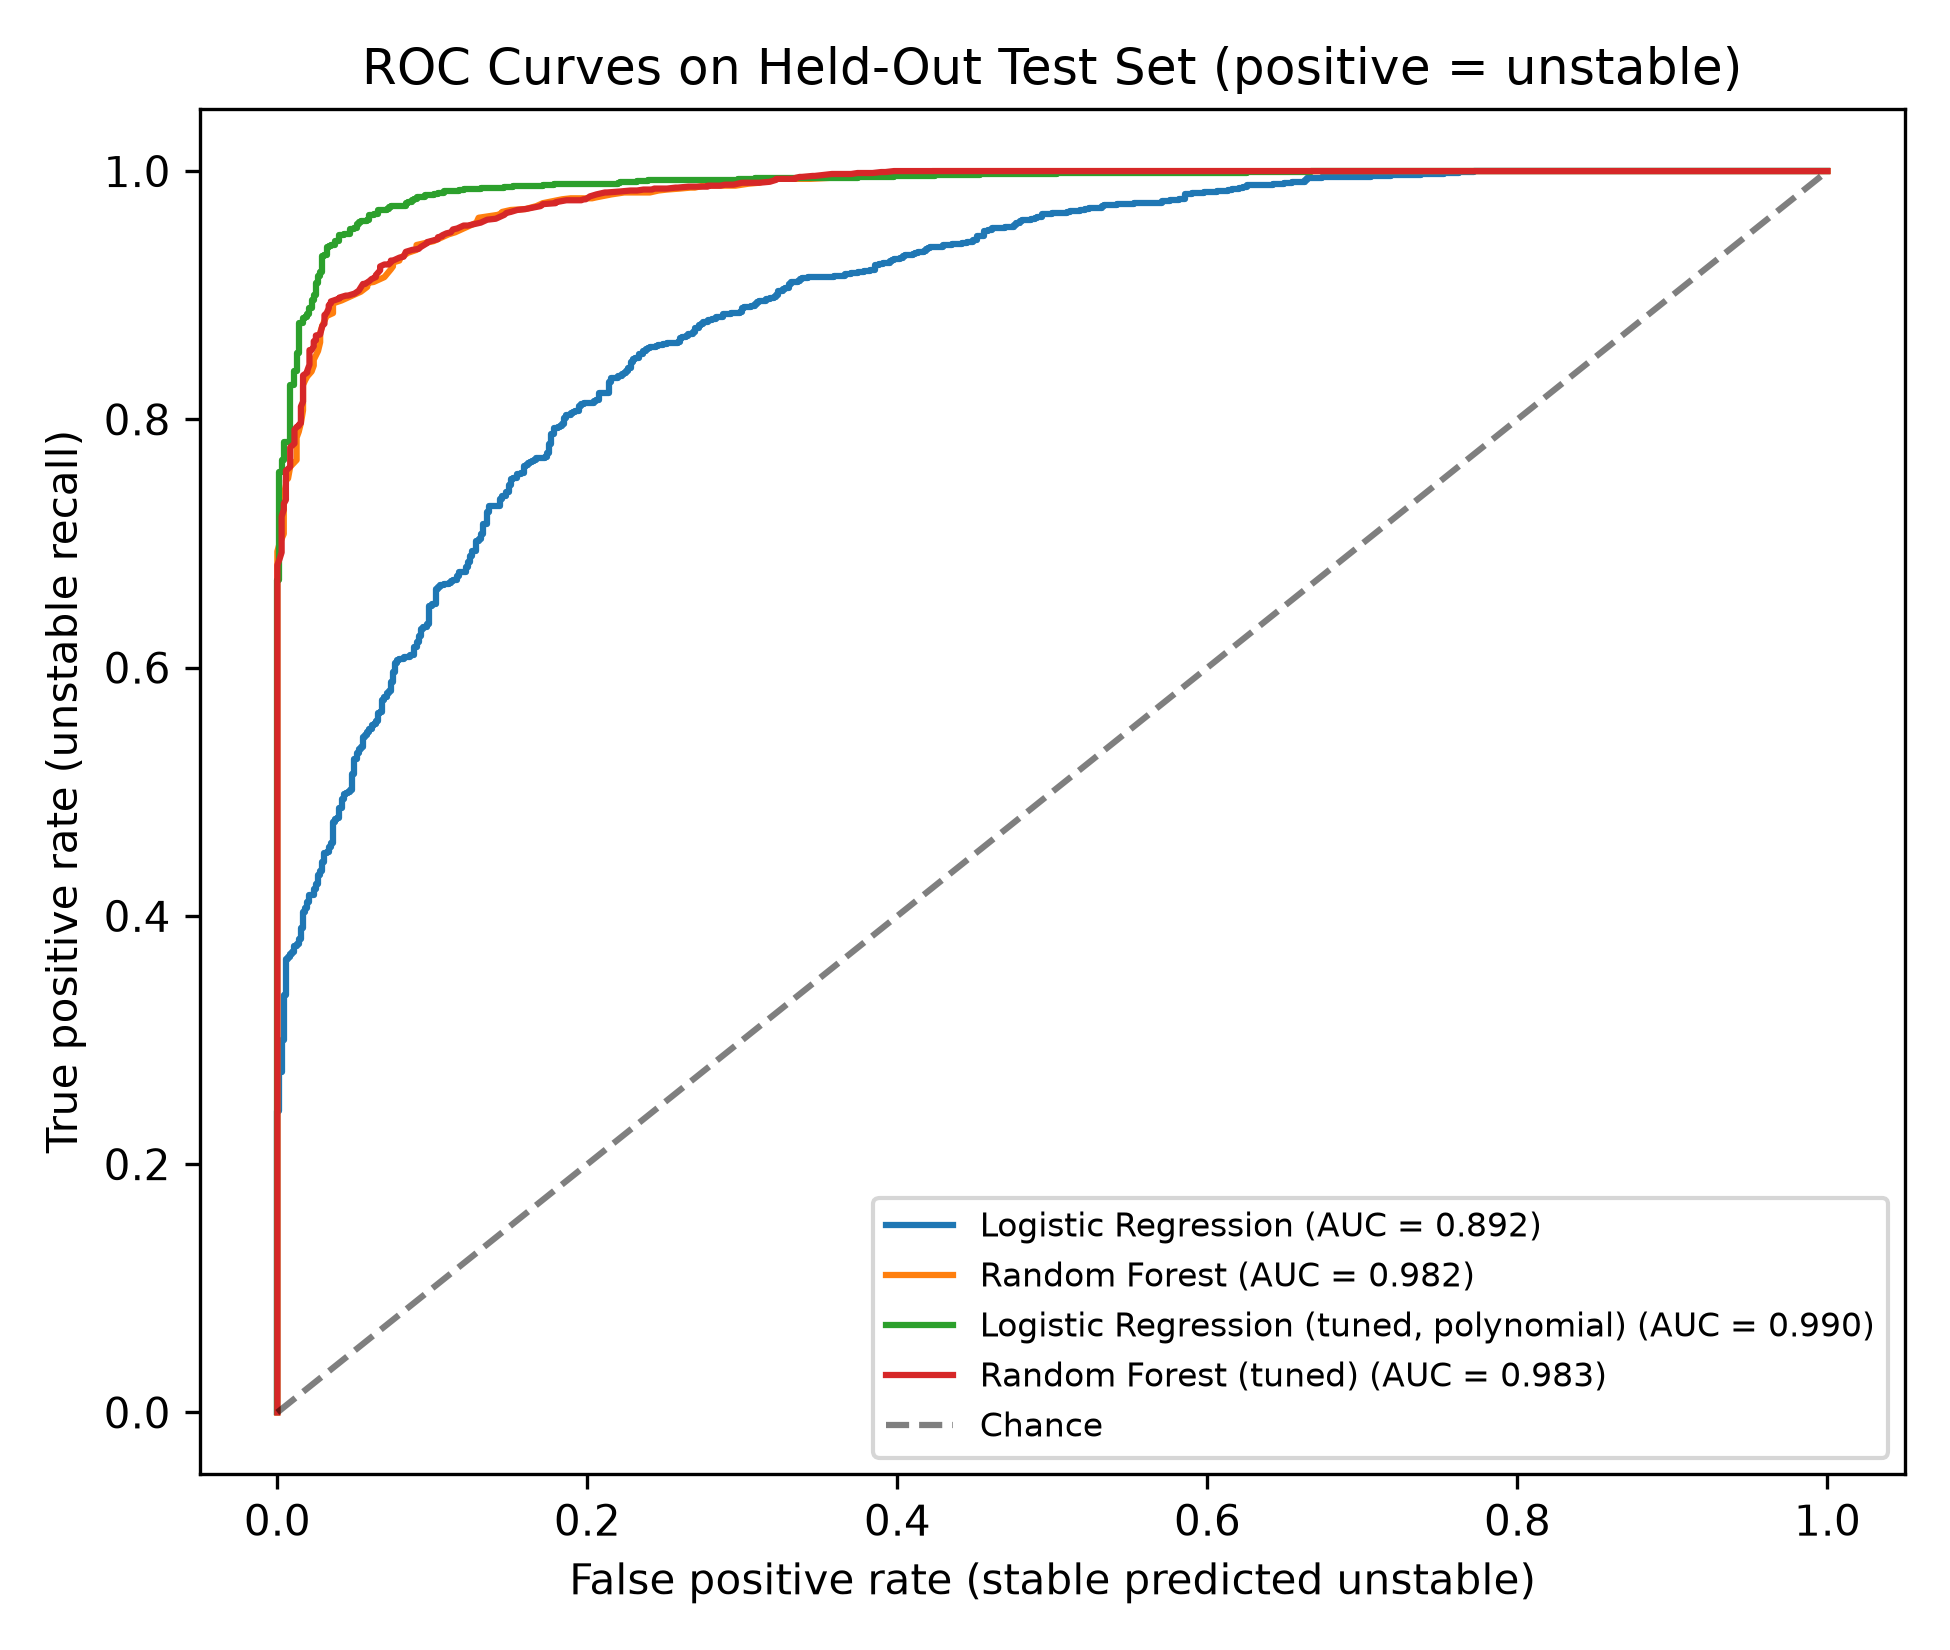

In [8]:
Image(str(PROJECT_ROOT / "outputs" / "figures" / "roc_curves.png"), width=600)

**Interpretation:**
- **Tuned Logistic Regression with polynomial features is the best model** on the test set
  (≈ 95.6% accuracy, macro-F1 ≈ 0.95, AUC ≈ 0.99), ahead of both the baseline and tuned Random Forest
  (≈ 92.6–92.9%). The CV ranking predicted this, so the conclusion is not driven by the test set.
- This matches the physics: the stability condition of the underlying differential equations
  depends on products of delays and elasticities, which a quadratic feature space represents directly.
  Random Forest approximates the same interactions with axis-aligned splits, which needs many trees
  and leaves a ragged boundary.
- With the recall-oriented threshold, missed instabilities fall to under 20 for both tuned models
  (out of 1,276 unstable test grids), at the cost of more false alarms. Which operating point is
  better depends on the relative cost of a missed instability vs an unnecessary intervention.

## 6. Permutation importance

Model,Logistic Regression,Random Forest
feature,,
tau1,0.0596,0.1207
tau4,0.0678,0.1158
tau2,0.0577,0.1095
tau3,0.0537,0.1085
g2,0.0579,0.0937
g4,0.0495,0.0884
g3,0.0599,0.0883
g1,0.0461,0.0771
p1,0.0002,0.0023


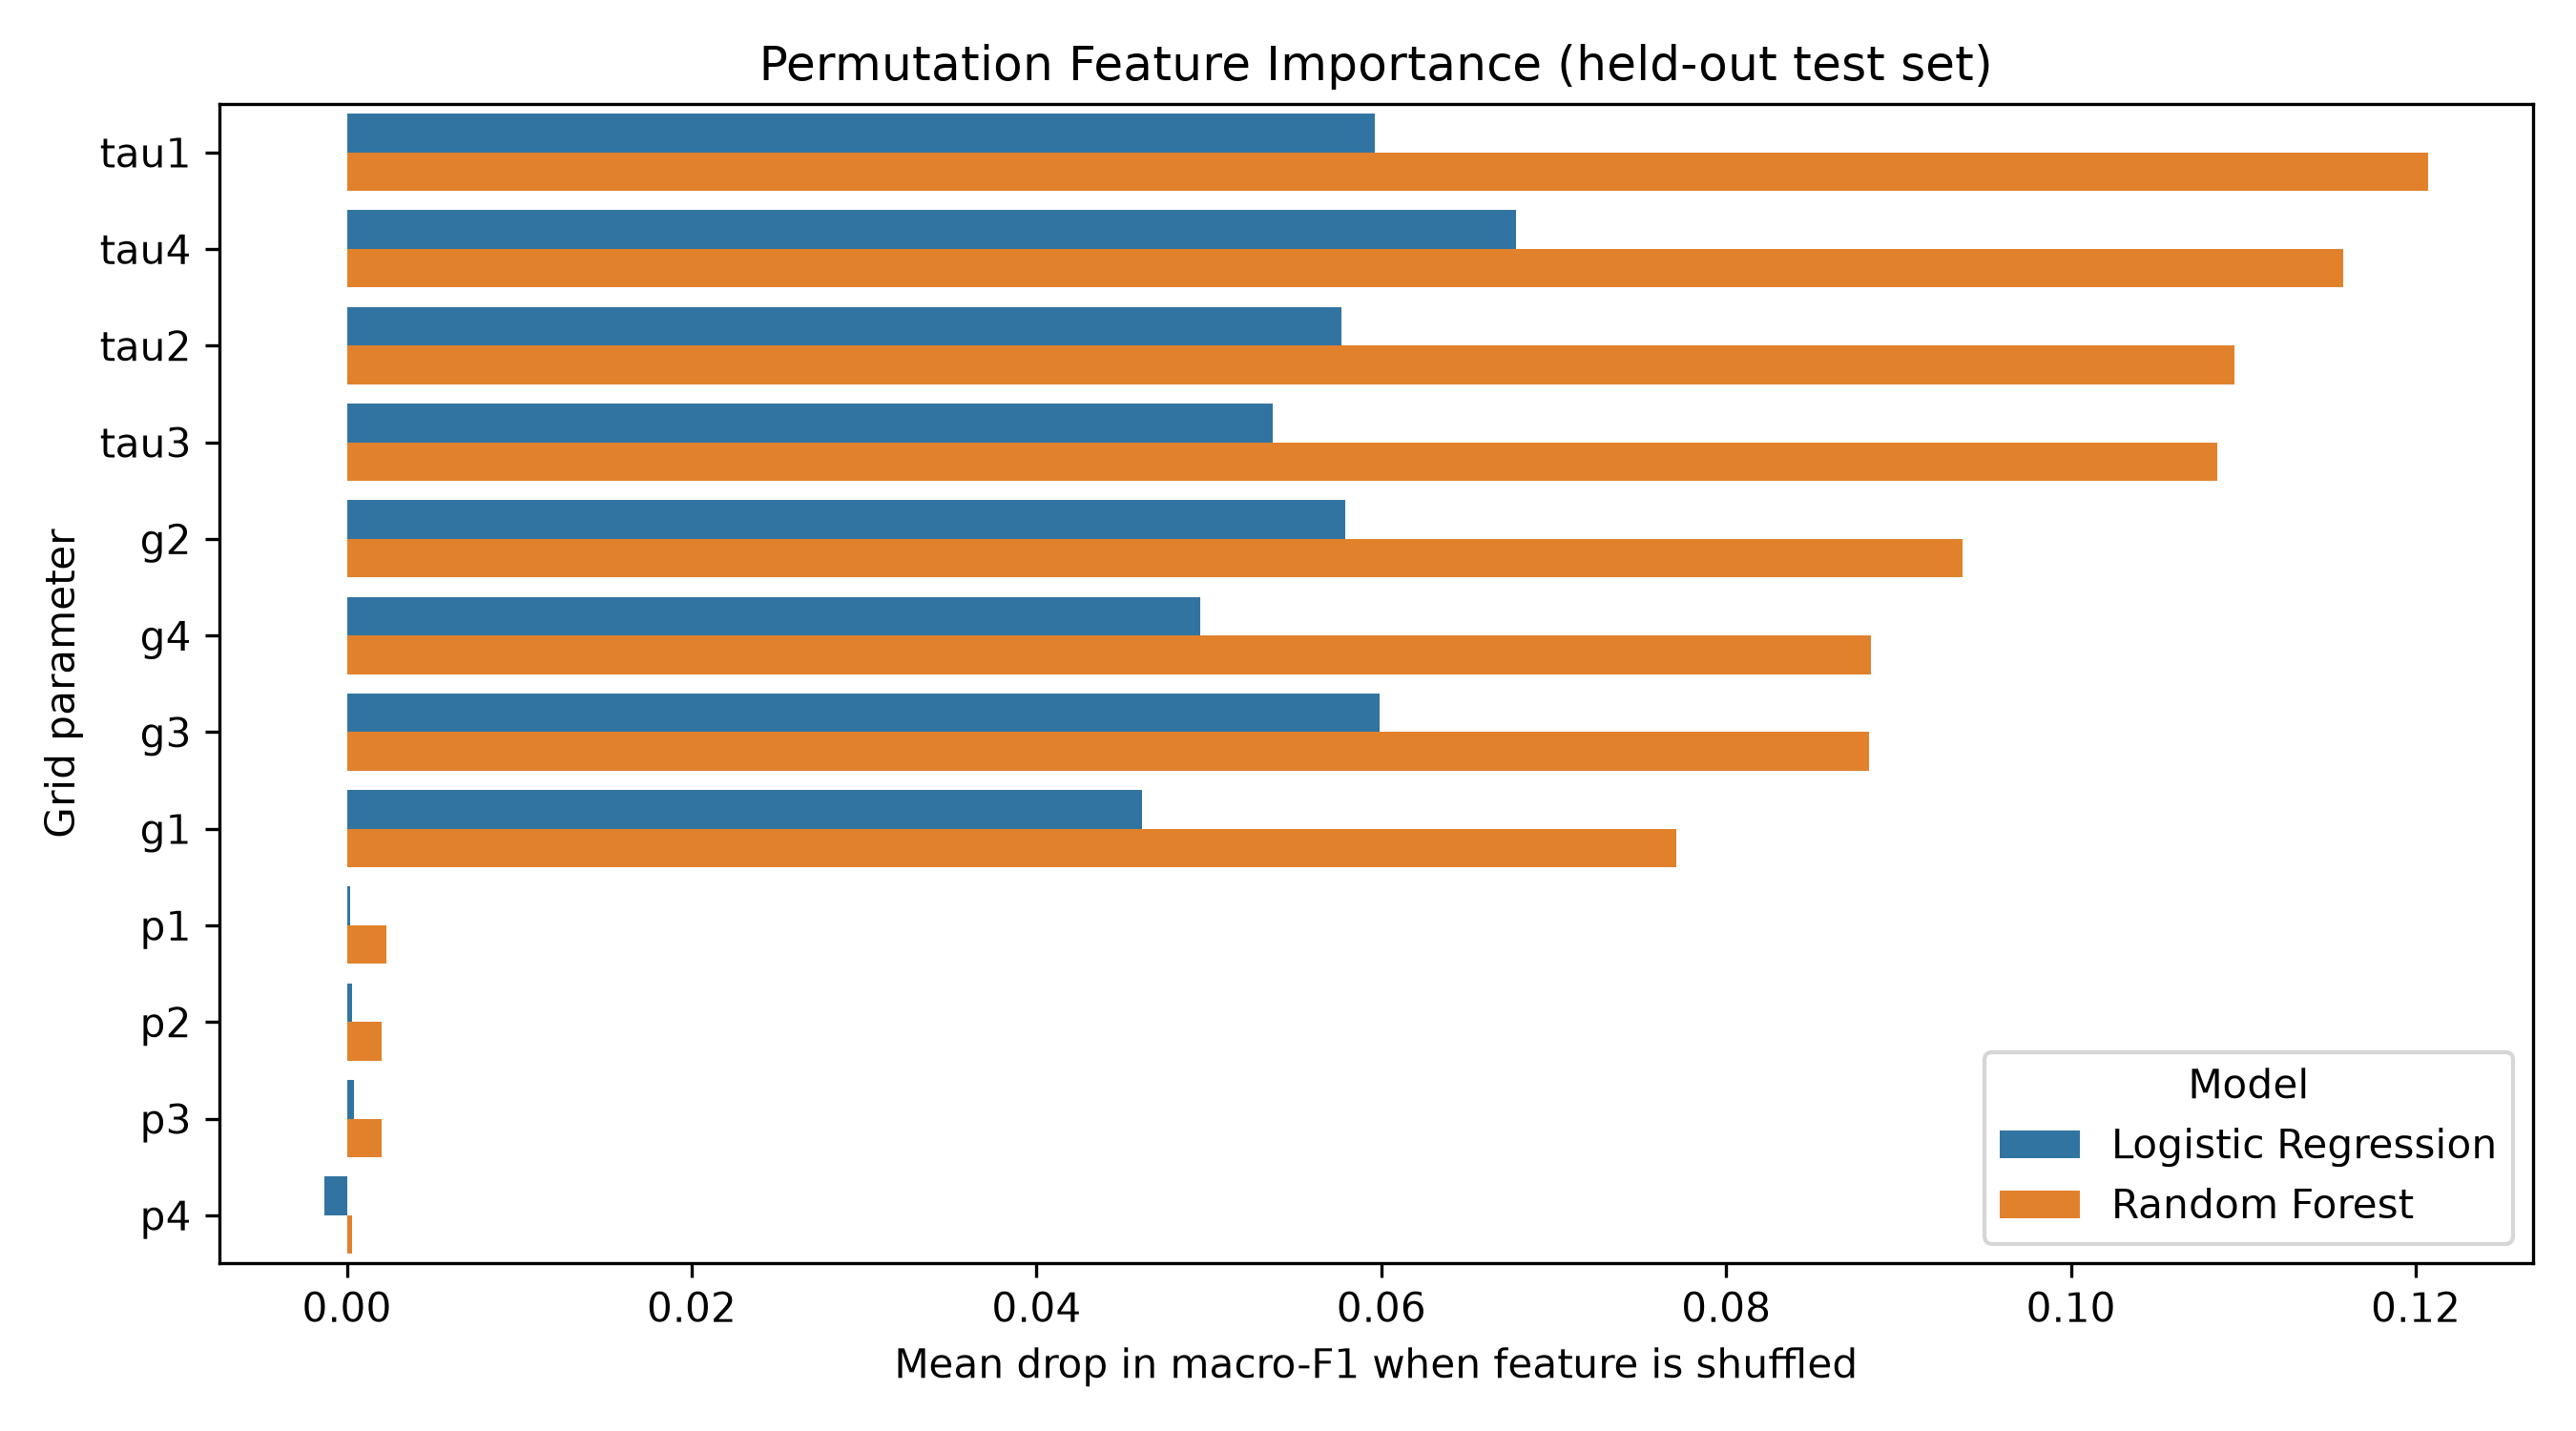

In [9]:
display(R["permutation"].pivot(index="feature", columns="Model", values="importance_mean")
        .sort_values("Random Forest", ascending=False).round(4))
Image(str(PROJECT_ROOT / "outputs" / "figures" / "permutation_importance.png"), width=750)

**Interpretation:** shuffling any `tau` or `g` feature substantially lowers macro-F1, while shuffling a
`p` feature has almost no effect. This confirms the MDI ranking from notebook 05 with a method that is
not biased towards continuous features.